# 05 — Hyperparameter Tuning, Calibration, Single-Pass Holdout Evaluation & SHAP Explainability

Summarizes Phase 5–6 validation tuning, calibration comparison, validation-only threshold selection, single-pass evaluation on the locked holdout test set (`n=114`), bootstrap 95% confidence intervals, and SHAP global + local explainability.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from liver_disease.config import DEFAULT_MODEL_ARTIFACT_PATH, FIGURES_DIR, REPORTS_DIR
from liver_disease.models.predict import LiverDiseasePredictor
from liver_disease.utils.io import load_json

report = load_json(REPORTS_DIR / 'final_evaluation_report.json')
meta = report['model_metadata']
ev = meta['evaluation_metrics']

print('=== Tuned Candidates Repeated-CV Comparison ===')
df_tuned = pd.read_csv(REPORTS_DIR / 'tuned_candidates_cv_comparison.csv')
display(df_tuned[['candidate', 'selection_score', 'roc_auc_mean', 'pr_auc_mean', 'balanced_accuracy_mean', 'brier_score_mean']])

print('=== Calibration Comparison (CV) ===')
display(pd.DataFrame(ev['calibration_comparison'])[['calibration', 'brier_score_mean', 'roc_auc_mean', 'pr_auc_mean']])

E:\Ahmed\DataScience\PythonProjects\Liver Disease\Antigravity\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== Tuned Candidates Repeated-CV Comparison ===


,candidate,selection_score,roc_auc_mean,pr_auc_mean,balanced_accuracy_mean,brier_score_mean
0,SoftVoting_ET_RF_LR,0.8165,0.7417,0.8912,0.5867,0.1765
1,ExtraTrees_Tuned,0.8158,0.7408,0.8908,0.6298,0.1797
2,LogisticRegression_Tuned,0.8079,0.7328,0.8830,0.5233,0.1774
3,CatBoost_Tuned,0.8048,0.7289,0.8807,0.6762,0.2007
4,RandomForest_Tuned,0.8018,0.7228,0.8809,0.5575,0.1820


=== Calibration Comparison (CV) ===


,calibration,brier_score_mean,roc_auc_mean,pr_auc_mean
0,none,0.1765,0.7417,0.8912
1,sigmoid,0.1783,0.7418,0.8913
2,isotonic,0.1791,0.7363,0.8853


In [2]:
print('Selected Model:', meta['model_name'], '| Calibration:', meta['calibration_method'], '| Selected Threshold:', meta['decision_threshold'])
for label, key in [
    ('Holdout Test @ Default Threshold (0.50)', 'holdout_test_default_threshold_0_50'),
    (f"Holdout Test @ Validation-Selected Threshold ({meta['decision_threshold']:.2f})", 'holdout_test_selected_threshold'),
]:
    m = ev[key]
    print(f'\n--- {label} ---')
    for k in ['roc_auc', 'pr_auc', 'accuracy', 'balanced_accuracy', 'precision', 'recall_sensitivity', 'specificity', 'f1_score', 'brier_score', 'confusion_matrix']:
        print(f'  {k}: {m[k]}')

print('\n=== Holdout Test 95% Bootstrap Confidence Intervals ===')
display(pd.DataFrame(ev['holdout_test_bootstrap_95_ci']).T)

Selected Model: SoftVoting_ET_RF_LR | Calibration: none | Selected Threshold: 0.57

--- Holdout Test @ Default Threshold (0.50) ---
  roc_auc: 0.8066
  pr_auc: 0.9233
  accuracy: 0.7368
  balanced_accuracy: 0.5993
  precision: 0.7576
  recall_sensitivity: 0.9259
  specificity: 0.2727
  f1_score: 0.8333
  brier_score: 0.1571
  confusion_matrix: {'tn': 9, 'fp': 24, 'fn': 6, 'tp': 75}

--- Holdout Test @ Validation-Selected Threshold (0.57) ---
  roc_auc: 0.8066
  pr_auc: 0.9233
  accuracy: 0.7281
  balanced_accuracy: 0.665
  precision: 0.8049
  recall_sensitivity: 0.8148
  specificity: 0.5152
  f1_score: 0.8098
  brier_score: 0.1571
  confusion_matrix: {'tn': 17, 'fp': 16, 'fn': 15, 'tp': 66}

=== Holdout Test 95% Bootstrap Confidence Intervals ===


,mean,ci_lower,ci_upper,confidence_level,n_valid_bootstraps
roc_auc,0.8065,0.7233,0.8798,0.95,1000.0
pr_auc,0.9231,0.8769,0.9582,0.95,1000.0
accuracy,0.7277,0.6404,0.8070,0.95,1000.0
balanced_accuracy,0.6645,0.5654,0.7567,0.95,1000.0
precision,0.8034,0.7142,0.8824,0.95,1000.0
recall_sensitivity,0.8159,0.7284,0.9024,0.95,1000.0
specificity,0.5132,0.3427,0.6897,0.95,1000.0
f1_score,0.8086,0.7403,0.8715,0.95,1000.0


final_test_roc_pr_curves.png


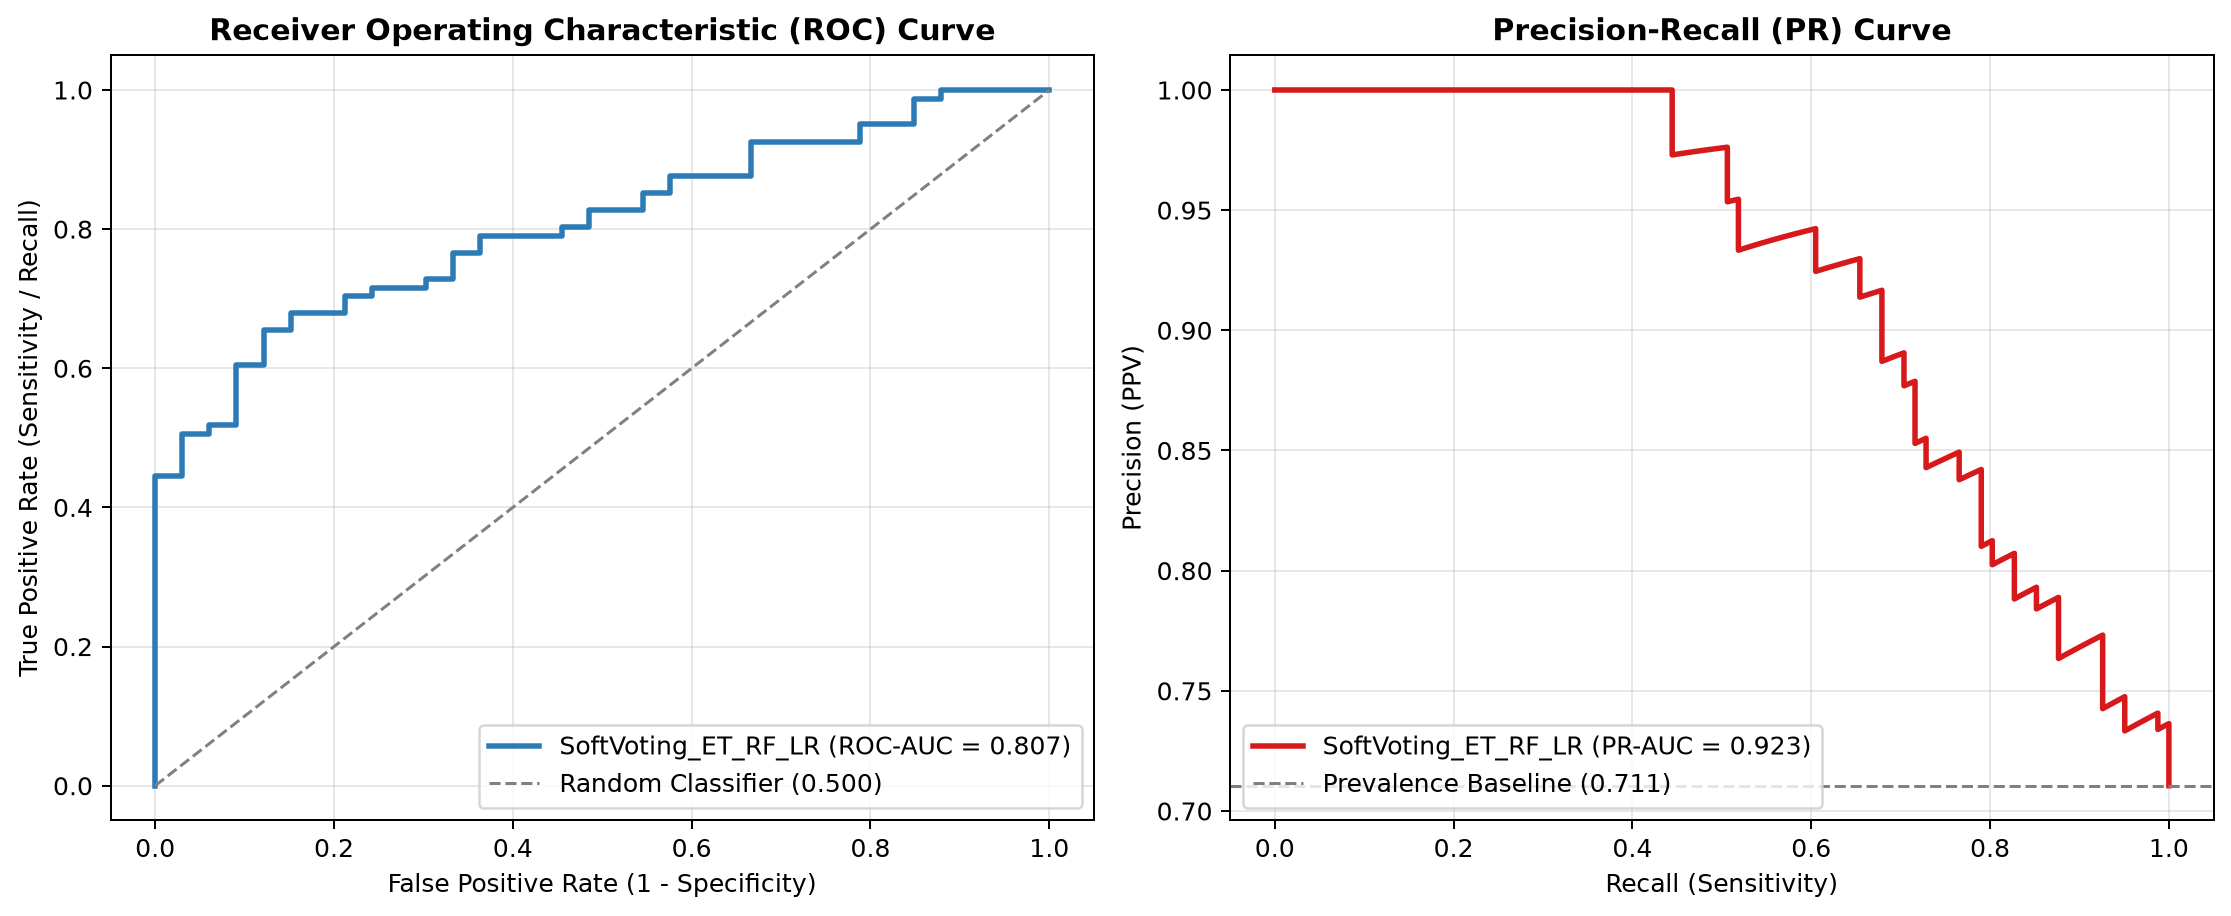

final_test_confusion_matrices.png


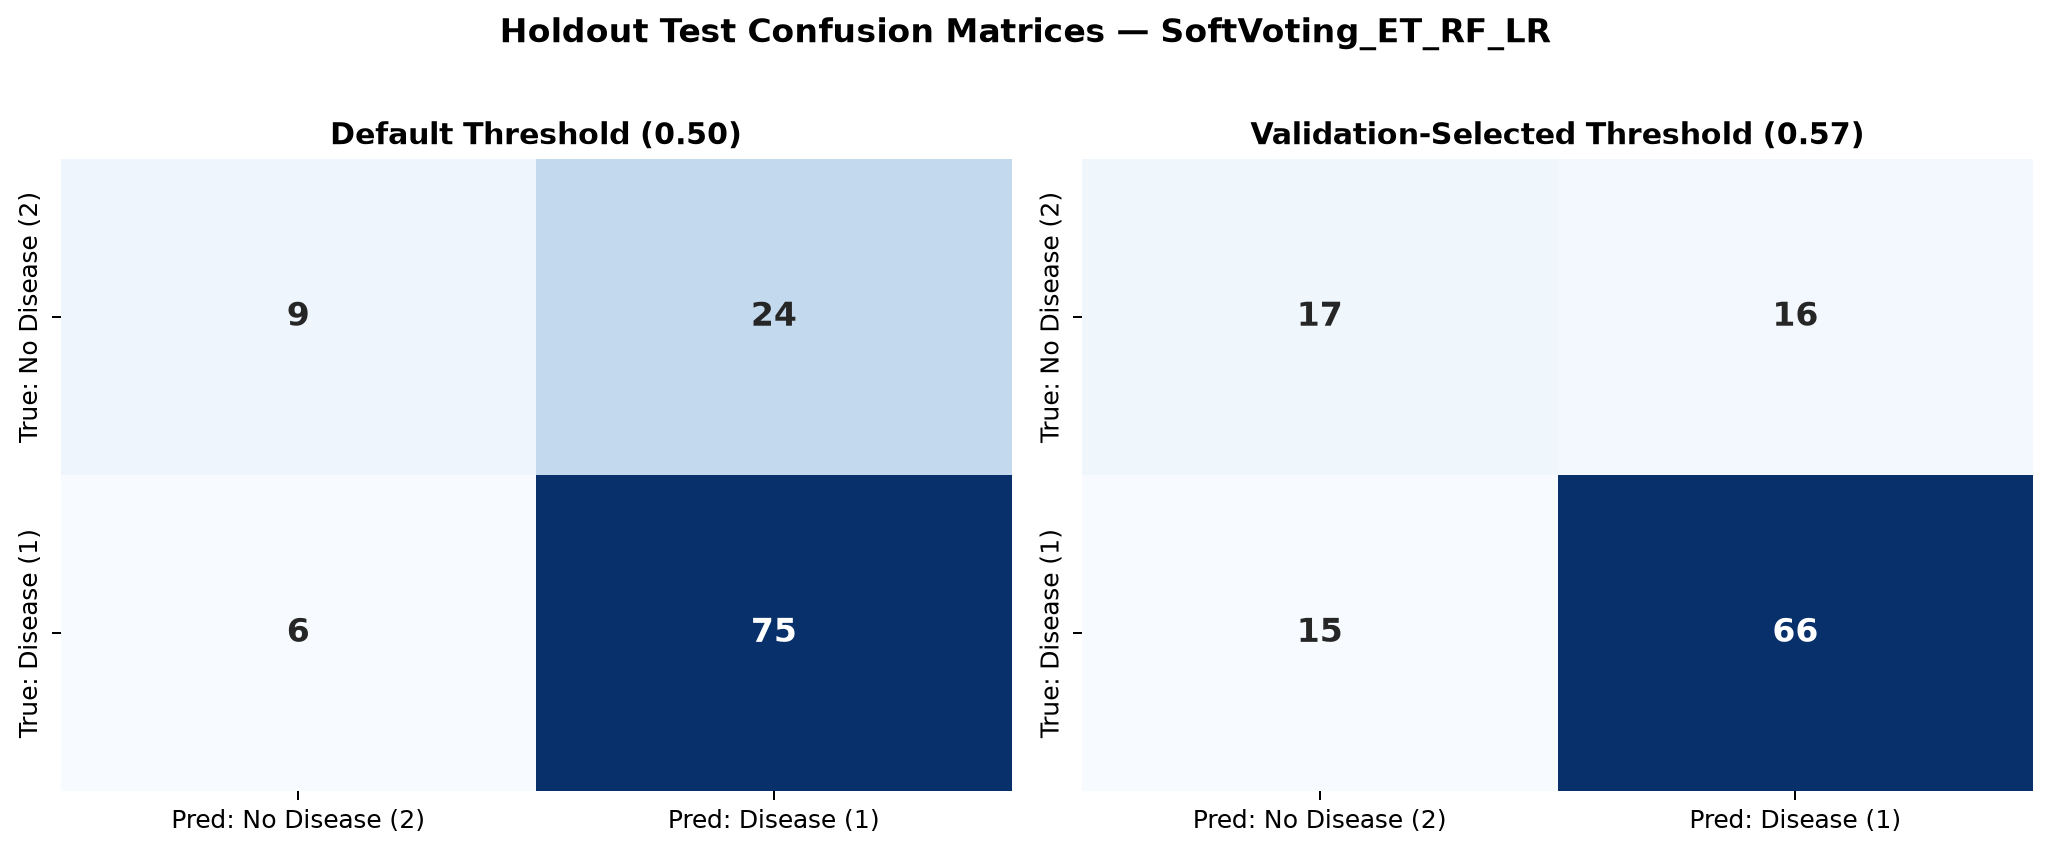

final_test_calibration_curve.png


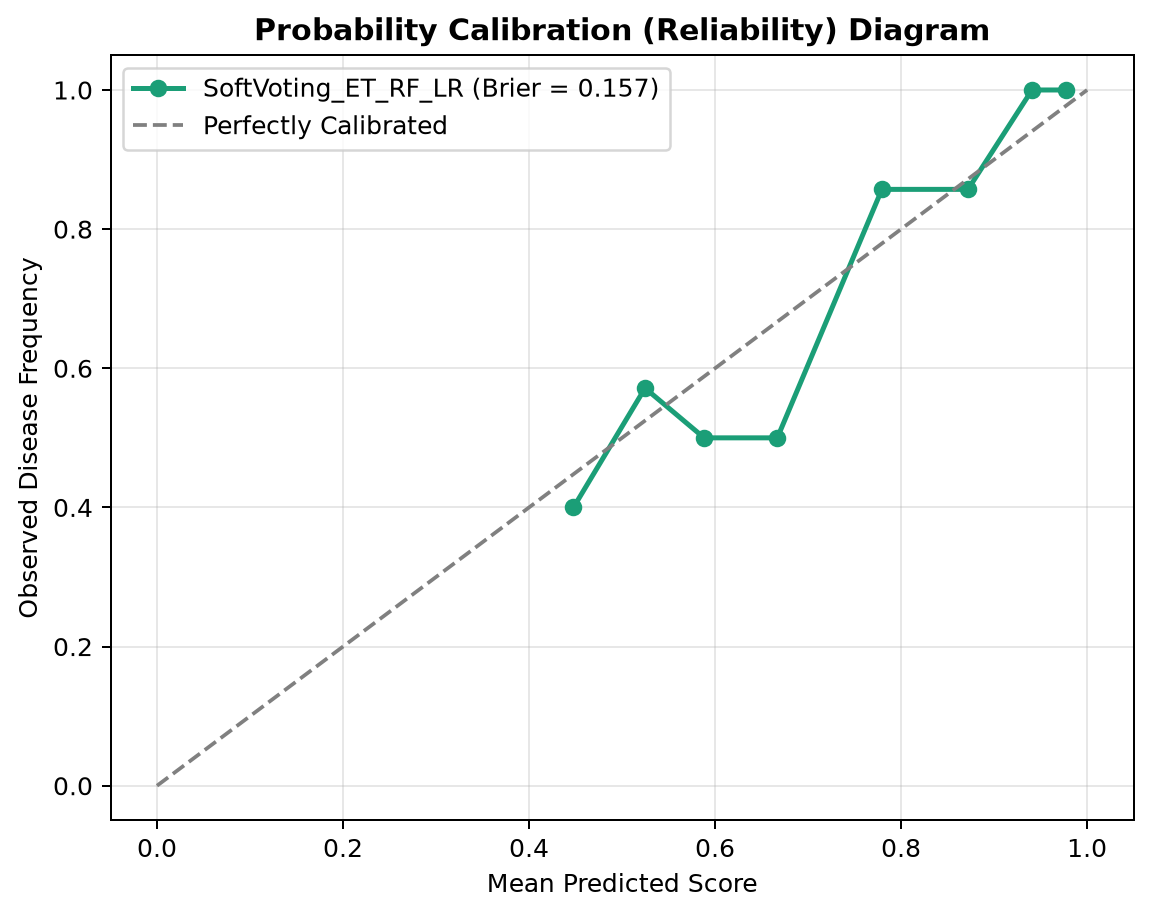

shap_summary_beeswarm.png


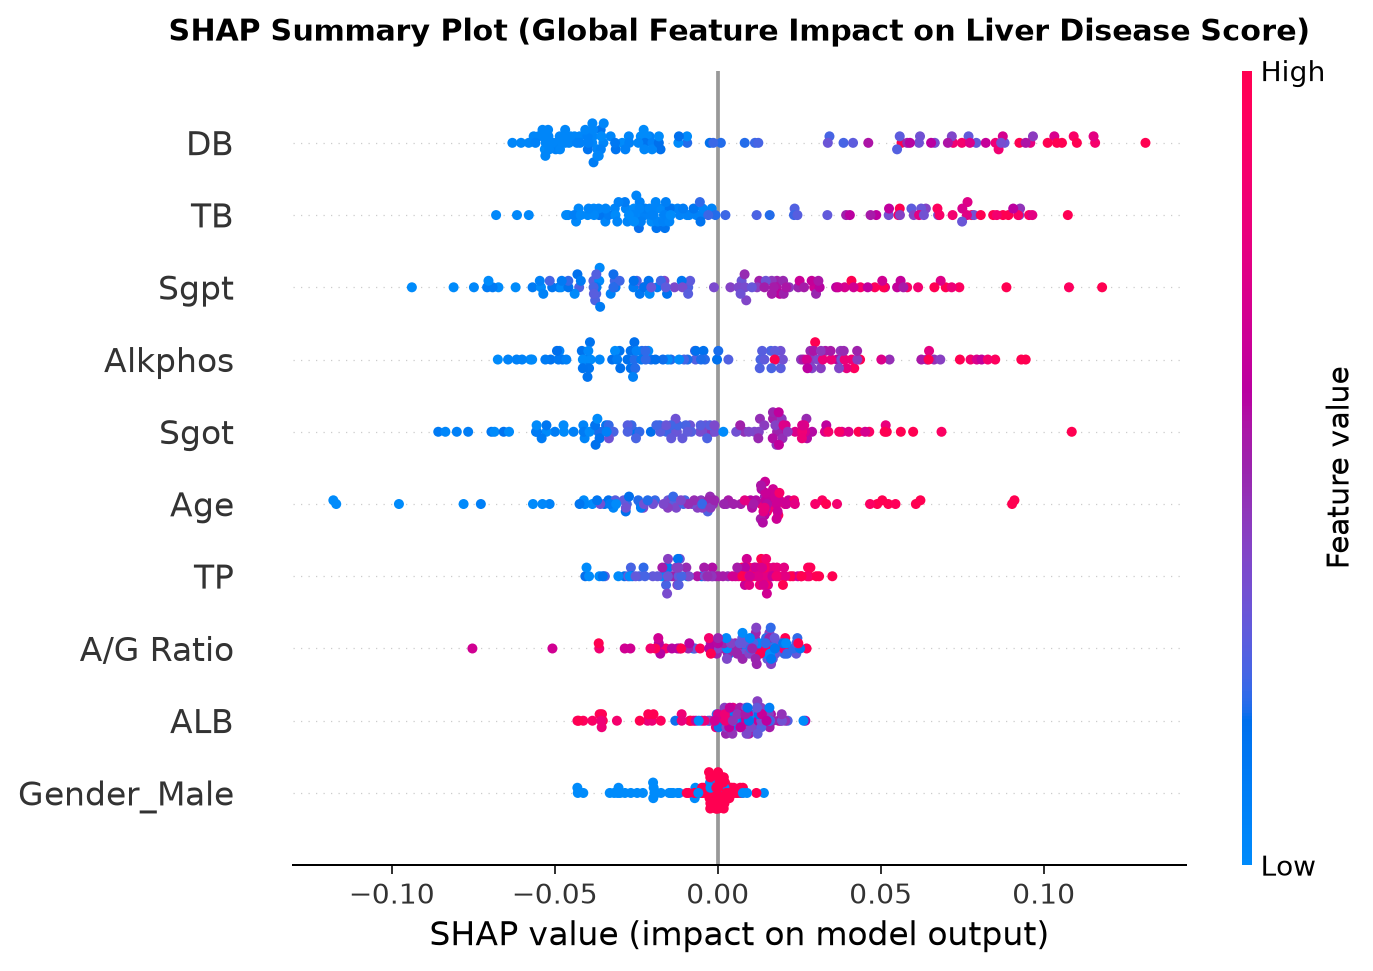

shap_global_importance_bar.png


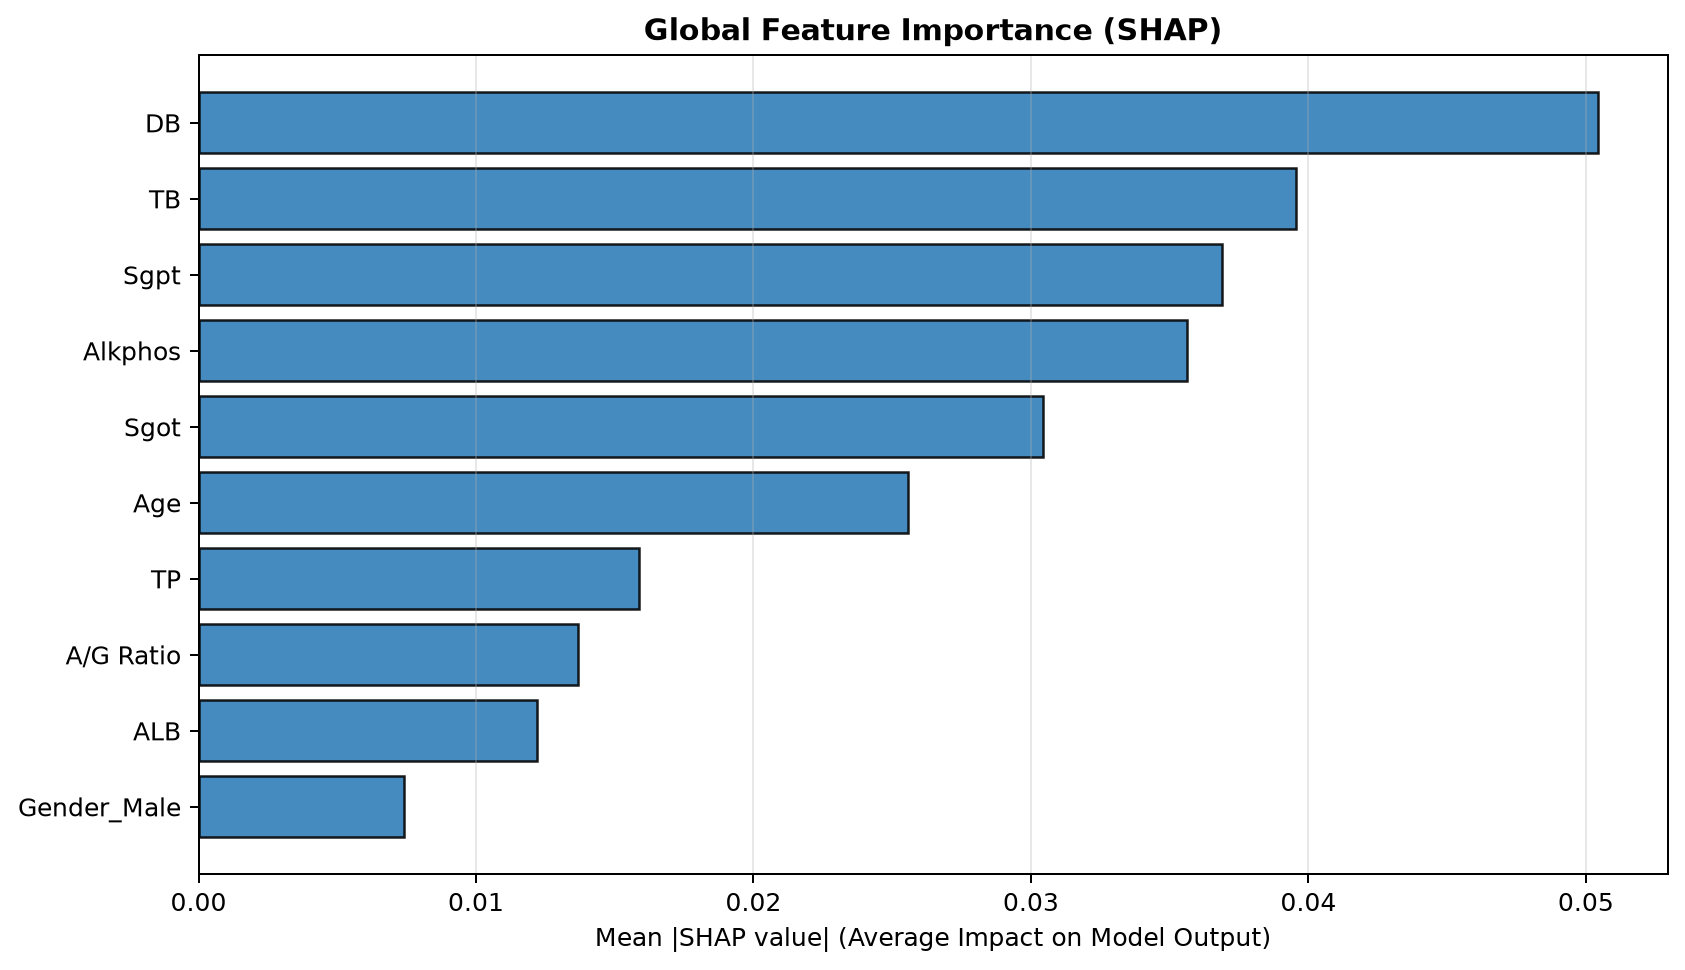

In [3]:
for img_name in [
    'final_test_roc_pr_curves.png',
    'final_test_confusion_matrices.png',
    'final_test_calibration_curve.png',
    'shap_summary_beeswarm.png',
    'shap_global_importance_bar.png',
]:
    print(img_name)
    display(Image(filename=str(FIGURES_DIR / img_name)))

In [4]:
predictor = LiverDiseasePredictor(DEFAULT_MODEL_ARTIFACT_PATH)
sample_patient = {
    'age': 62, 'gender': 'Male', 'total_bilirubin': 10.9, 'direct_bilirubin': 5.5,
    'alkaline_phosphotase': 699.0, 'alamine_aminotransferase': 64.0,
    'aspartate_aminotransferase': 100.0, 'total_proteins': 7.5,
    'albumin': 3.2, 'albumin_and_globulin_ratio': 0.74,
}
explained = predictor.explain_one(sample_patient, top_k=5)
print('Prediction:', explained['prediction'], explained['prediction_label'], '| Prob:', explained['probability'], '| Risk:', explained['risk_category'])
display(pd.DataFrame(explained['explanation']['top_contributing_features']))

Prediction: 1 Liver Disease | Prob: 0.9823 | Risk: High


,feature,raw_value,transformed_value,shap_value,abs_impact,direction
0,DB,5.5,2.6552,0.08043,0.08043,increases_risk
1,TB,10.9,2.9064,0.05365,0.05365,increases_risk
2,Alkphos,699.0,2.3864,0.04737,0.04737,increases_risk
3,Sgpt,64.0,0.6569,0.02164,0.02164,increases_risk
4,ALB,3.2,0.0833,0.01674,0.01674,increases_risk
